# P2.4 — Benchmark des 5 modèles (T2)
**Question** : parmi cinq algorithmes, lequel sépare le mieux les fraudes des transactions légitimes ?

| Étape | Durée prévue |
|---|---|
| 1. Protocole d'évaluation commun | 1,5 j |
| 2. Régression logistique + Random Forest | 1,5 j |
| 3. Gradient boosting (XGBoost) | 1 j |
| 4. SVM RBF (sur sous-échantillon) | 1,5 j |
| 5. MLP | 1 j |
| 6. Réglage léger des hyperparamètres (optionnel ici) | 1 j |
| 7. Tableau comparatif | 0,5 j |

**Ce que ce notebook ne fait pas** : il ne désigne pas le champion. Il classe les modèles ; la **preuve statistique** (Friedman, Wilcoxon, Holm) vient en P2.5. L'enregistrement dans MLflow viendra ensuite, à partir des fichiers CSV produits ici.

Le code réutilisable est dans `src/benchmark.py` (P2.5 l'utilisera avec 10 plis × 5 répétitions).

## 1. Chargement et réglages

In [1]:
import sys, time
sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from src.data_prep import SEED, load_clean, make_splits, build_preprocessor
from src.benchmark import (MODELS, LABELS, display_names, cross_validate_model, summarize, compute_metrics,
                           latency_ms, make_pipeline, check_xgboost, save_best_params)

N_SPLITS = 5             # plis de validation croisée (mets 3 si ton PC est trop lent)
TUNE_SPLITS = 3          # plis pour le réglage léger
SVM_N_MAJORITY = 15000   # transactions légitimes conservées pour entraîner le SVM
RUN_TUNING = False       # True = réglage léger des hyperparamètres (long)

OUT = Path("../artifacts/benchmark")
OUT.mkdir(parents=True, exist_ok=True)

df = load_clean("../datasets/creditcard.csv")
splits = make_splits(df)
X_train, y_train = splits["train"]
X_cal, y_cal = splits["cal"]
print({k: (len(v[1]), int(v[1].sum())) for k, v in splits.items()})
print("Le lot de TEST n'est pas utilisé dans ce notebook.")

{'train': (170235, 284), 'cal': (56745, 94), 'test': (56746, 95)}
Le lot de TEST n'est pas utilisé dans ce notebook.


## 2. Le protocole (identique pour les 5 modèles)
- **Mêmes données** : le lot d'entraînement (170 235 lignes) et le même prétraitement (log de `Amount`, standardisation), appris dans chaque pli.
- **Validation croisée stratifiée à 5 plis** : chaque pli de validation contient environ 57 fraudes. Chaque modèle est entraîné 5 fois, chaque fois évalué sur des données qu'il n'a pas vues.
- **Mesures** : PR-AUC (critère principal), ROC-AUC, F1 et MCC (au seuil 0,5), Brier (qualité des probabilités, plus bas = mieux), temps d'entraînement.
- **Aucun rééquilibrage** (décision de P2.2), sauf pour le SVM (voir plus bas).

## 3. XGBoost fonctionne-t-il dans cet environnement ?
Lors de P2.3, XGBoost 3.2.0 avait produit un modèle **constant**. On le teste ici avec quelques variantes (hypothèses : point de départ du modèle, méthode de construction des arbres, poids minimal des feuilles). S'il n'y en a aucune de saine, on utilise **HistGradientBoosting** de scikit-learn : la consigne parle de « Gradient Boosting/XGBoost ».

In [2]:
prep_check = build_preprocessor(include_time=False)
Z_train = prep_check.fit_transform(X_train)
Z_cal = prep_check.transform(X_cal)

xgb_ok, XGB_PARAMS, xgb_report, xgb_info = check_xgboost(Z_train, y_train, Z_cal, y_cal)
print(xgb_info)
xgb_report.to_csv(OUT / "xgboost_check.csv", index=False)
xgb_report

xgboost 3.2.0


,variante,PR-AUC,valeurs distinctes,sain
0,défaut,0.8868,54617,True
1,base_score=0.5,0.8892,53921,True
2,tree_method=approx,0.8811,54637,True
3,min_child_weight=0.01,0.8726,54287,True
4,base_score=0.5 + min_child_weight=0.01,0.8881,53329,True


In [3]:
GB_KIND = "xgboost" if xgb_ok else "hist"
NAMES = display_names(GB_KIND)
common = dict(gb_kind=GB_KIND, xgb_params=XGB_PARAMS, svm_n_majority=SVM_N_MAJORITY)

print("Gradient boosting retenu :", NAMES["gb"])
if xgb_ok:
    print("Variante saine d'XGBoost :", XGB_PARAMS or "réglages par défaut")
else:
    print("Aucune variante saine (ou xgboost absent) : HistGradientBoosting utilisé. À noter dans le README.")

Gradient boosting retenu : XGBoost
Variante saine d'XGBoost : réglages par défaut


## 4. Les cinq modèles
| Modèle | Réglages (identiques pour tous les modèles de la même famille) | Remarque |
|---|---|---|
| Régression logistique | `max_iter=1000` | Rapide, probabilités bien calibrées |
| Random Forest | 100 arbres | Probabilités souvent trop « tranchées » |
| Gradient boosting | 200 arbres, taux d'apprentissage 0,1 | Souvent le meilleur sur données tabulaires |
| SVM (RBF) | entraîné sur **toutes les fraudes + 15 000 légitimes** tirées au hasard | Trop lent sur 170 000 lignes. Les probabilités sont **corrigées** du biais du sous-échantillonnage (formule de Dal Pozzolo et al., 2015) |
| MLP | 2 couches de 64 neurones, arrêt anticipé | Réseau de neurones simple |

**Durée** : compte 15 à 30 minutes pour la cellule suivante. Ne l'interromps pas : les résultats de chaque modèle sont enregistrés dans `artifacts/benchmark/`, donc en cas de plantage, la relance reprend où elle s'est arrêtée.

In [4]:
all_cv = []
t_total = time.time()
for key in MODELS:
    print(f"\n=== {NAMES[key]} ===")
    all_cv.append(cross_validate_model(key, X_train, y_train, n_splits=N_SPLITS, cache_dir=OUT, **common))

cv_results = pd.concat(all_cv, ignore_index=True)
cv_results.to_csv(OUT / "cv_results.csv", index=False)
print(f"\nTerminé en {(time.time() - t_total) / 60:.1f} min")


=== Régression logistique ===
  (résultats déjà calculés, chargés depuis cv_logreg_base_5x1.csv)

=== Random Forest ===
  (résultats déjà calculés, chargés depuis cv_rf_base_5x1.csv)

=== XGBoost ===
  (résultats déjà calculés, chargés depuis cv_gb_xgboost_5x1.csv)

=== SVM (RBF) ===
  (résultats déjà calculés, chargés depuis cv_svm_n15000_5x1.csv)

=== MLP ===
  (résultats déjà calculés, chargés depuis cv_mlp_base_5x1.csv)

Terminé en 0.0 min


## 5. Résultats de la validation croisée (moyenne ± écart-type sur les plis)

In [6]:
table, agg = summarize(cv_results, NAMES)
table.to_csv(OUT / "summary_cv.csv")

for key in MODELS:
    if agg.loc[key, ("roc_auc", "mean")] < 0.8:
        print(f"ATTENTION : {NAMES[key]} a une ROC-AUC moyenne < 0,8 : modèle suspect (dégénéré ?)")
table

,PR-AUC,ROC-AUC,"F1 (seuil 0,5)","MCC (seuil 0,5)",Brier,Entraînement (s)
XGBoost,0.8317 ± 0.0916,0.9798 ± 0.0174,0.8469 ± 0.0523,0.8506 ± 0.0513,0.000425 ± 0.000147,4.9
Random Forest,0.8260 ± 0.0839,0.9348 ± 0.0411,0.8366 ± 0.0439,0.8406 ± 0.0411,0.000454 ± 0.000111,44.5
MLP,0.7984 ± 0.0585,0.9671 ± 0.0203,0.7704 ± 0.0234,0.7758 ± 0.0195,0.000560 ± 0.000074,27.4
SVM (RBF),0.7534 ± 0.1012,0.9649 ± 0.0149,0.7492 ± 0.0549,0.7508 ± 0.0534,0.000701 ± 0.000151,13.2
Régression logistique,0.7352 ± 0.0652,0.9788 ± 0.0175,0.6978 ± 0.0386,0.7096 ± 0.0371,0.000720 ± 0.000073,0.9


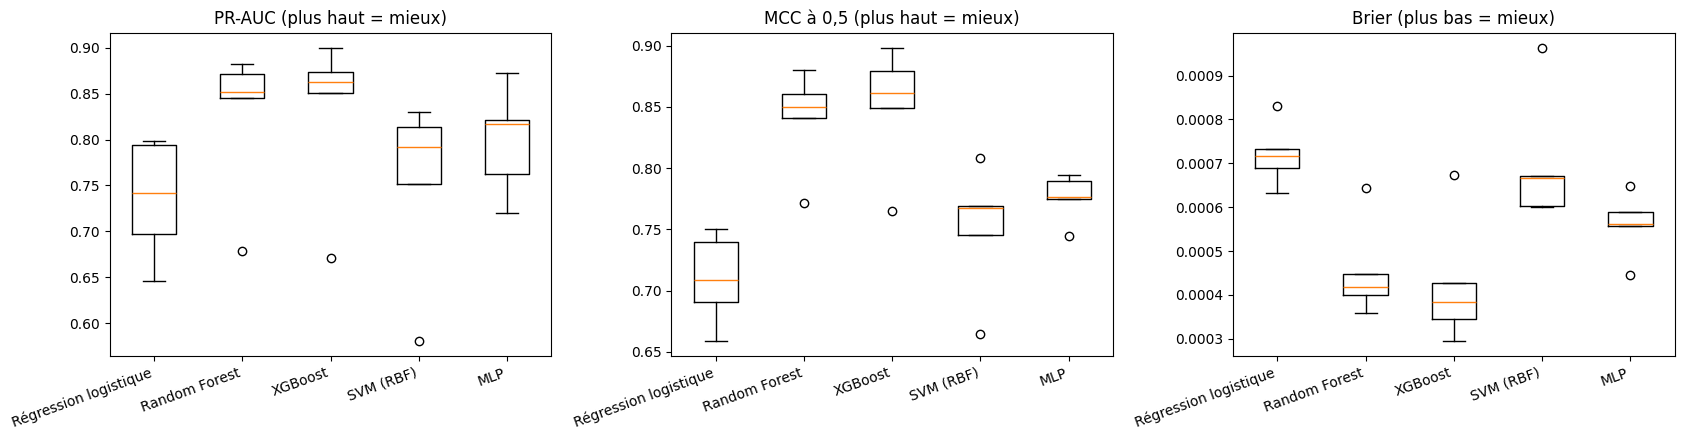

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
panels = [("pr_auc", "PR-AUC (plus haut = mieux)"), ("mcc", "MCC à 0,5 (plus haut = mieux)"),
          ("brier", "Brier (plus bas = mieux)")]
for a, (metric, title) in zip(ax, panels):
    a.boxplot([cv_results.loc[cv_results["model"] == k, metric] for k in MODELS])
    a.set_xticklabels([NAMES[k] for k in MODELS], rotation=20, ha="right")
    a.set_title(title)
plt.tight_layout()
plt.savefig(OUT / "benchmark_boxplots.png", dpi=120)
plt.show()

### Comment lire ce tableau
1. **Commence par la PR-AUC.** Le hasard donnerait ≈ 0,0017.
2. **Compare l'écart entre deux modèles à l'écart-type.** Avec ~57 fraudes par pli, les écarts-types sont élevés : si deux modèles sont séparés de moins d'un écart-type, **on ne peut rien conclure** (c'est justement le rôle de P2.5).
3. **F1 et MCC dépendent du seuil 0,5.** Un modèle aux probabilités mal calibrées peut avoir un MCC bas sans être mauvais pour classer (PR-AUC).
4. **Brier** mesure la fiabilité des probabilités : important pour la règle de décision (seuils 0,5 et 0,9) et pour le conformal (P2.6).
5. **Les boîtes** montrent la dispersion sur les plis : une grande boîte = résultat instable.

## 6. Réglage léger des hyperparamètres (optionnel)
Pour chaque modèle, 3 ou 4 configurations sont comparées par validation croisée à 3 plis ; on retient la meilleure PR-AUC. **Même budget pour tous les modèles**, pour ne pas en favoriser un. Limite : on règle et on compare sur les mêmes données, ce qui est légèrement optimiste ; P2.5 refera la comparaison avec d'autres découpages.

Mets `RUN_TUNING = True` dans la première cellule pour l'activer (compte 20 à 40 minutes de plus).

In [8]:
BEST_PARAMS = {}

if RUN_TUNING:
    GRIDS = {
        "logreg": [{"C": 0.01}, {"C": 0.1}, {"C": 1.0}, {"C": 10.0}],
        "rf": [{"min_samples_leaf": 1}, {"min_samples_leaf": 3}, {"min_samples_leaf": 10}],
        "gb": [{"max_depth": 3}, {"max_depth": 6}, {"max_depth": 10}],
        "svm": [{"C": 0.5}, {"C": 1.0}, {"C": 5.0}],
        "mlp": [{"hidden_layer_sizes": (32,)}, {"hidden_layer_sizes": (64, 64)}, {"hidden_layer_sizes": (128, 64)}],
    }
    rows = []
    for key in MODELS:
        for params in GRIDS[key]:
            print(f"\n=== {NAMES[key]} {params} ===")
            res = cross_validate_model(key, X_train, y_train, n_splits=TUNE_SPLITS, cache_dir=OUT, **common, **params)
            rows.append({"modèle": NAMES[key], "paramètres": str(params), "PR-AUC": round(res["pr_auc"].mean(), 4),
                         "écart-type": round(res["pr_auc"].std(), 4), "_key": key, "_params": params})
    tuning = pd.DataFrame(rows)
    for key in MODELS:
        sub = tuning[tuning["_key"] == key]
        BEST_PARAMS[key] = sub.loc[sub["PR-AUC"].idxmax(), "_params"]
    save_best_params(OUT / "best_params.json", BEST_PARAMS)
    tuning.drop(columns=["_key", "_params"]).to_csv(OUT / "tuning_results.csv", index=False)
    display(tuning.drop(columns=["_key", "_params"]))
    print("Configurations retenues :", BEST_PARAMS)
else:
    print("Réglage ignoré (RUN_TUNING = False) : réglages par défaut pour tous les modèles.")

Réglage ignoré (RUN_TUNING = False) : réglages par défaut pour tous les modèles.


## 7. Évaluation sur le lot de calibration + latence
Chaque modèle est entraîné **une fois** sur tout le lot d'entraînement, puis évalué sur le lot de **calibration** (le test reste intact). La latence est mesurée pour **une seule transaction**, sans parallélisme, comme en production. Repère : le service ML doit répondre bien en dessous de 800 ms.

In [9]:
rows = []
for key in MODELS:
    pipe = make_pipeline(key, **common, **BEST_PARAMS.get(key, {}))
    t0 = time.time()
    pipe.fit(X_train, np.asarray(y_train))   # y en tableau numpy (voir note sur XGBoost)
    fit_s = time.time() - t0
    proba = pipe.predict_proba(X_cal)[:, 1]
    if np.unique(proba).size < 10:
        print(f"ATTENTION : probabilités quasi constantes pour {NAMES[key]} (modèle dégénéré ?)")
    m = compute_metrics(y_cal, proba)
    rows.append({"modèle": NAMES[key], **{LABELS[k]: round(v, 4) for k, v in m.items()},
                 **latency_ms(pipe, X_cal), "entraînement (s)": round(fit_s, 1)})
    print(f"{NAMES[key]} : PR-AUC = {m['pr_auc']:.4f}")

holdout = pd.DataFrame(rows).set_index("modèle").sort_values(LABELS["pr_auc"], ascending=False)
holdout.to_csv(OUT / "holdout_calibration.csv")
holdout

Régression logistique : PR-AUC = 0.7978
Random Forest : PR-AUC = 0.8716
XGBoost : PR-AUC = 0.8868


c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM (RBF) : PR-AUC = 0.7955
MLP : PR-AUC = 0.8718


,PR-AUC,ROC-AUC,"F1 (seuil 0,5)","MCC (seuil 0,5)",Brier,latence médiane (ms),latence p95 (ms),entraînement (s)
modèle,,,,,,,,
XGBoost,0.8868,0.9789,0.8721,0.8757,0.0003,9.23,13.43,5.7
MLP,0.8718,0.9805,0.8475,0.8489,0.0004,13.68,17.65,25.7
Random Forest,0.8716,0.9509,0.8814,0.8829,0.0003,23.91,31.18,58.4
Régression logistique,0.7978,0.9747,0.7665,0.7723,0.0006,13.58,26.98,1.1
SVM (RBF),0.7955,0.9492,0.7979,0.7975,0.0006,11.32,15.08,11.5


**Prudence** : ce lot ne contient que **94 fraudes**. Un écart de quelques points de PR-AUC entre deux modèles est du bruit. Ce tableau sert à vérifier la cohérence avec la validation croisée et à comparer les latences, pas à désigner un gagnant.

## 8. Conclusions de P2.4
- **Gradient boosting utilisé** : XGBoost 3.2.0 aux réglages par défaut (200 arbres, taux 0,1), jugé sain par un diagnostic de 5 variantes (PR-AUC de 0,873 à 0,889 sur le lot de calibration, ~54 000 probabilités distinctes). L'échec observé en P2.3 n'était donc pas un défaut de la bibliothèque (cause exacte non identifiée).
- **Classement par PR-AUC (validation croisée stratifiée, 5 plis)** : 1. XGBoost 0,832 ± 0,092 ; 2. Random Forest 0,826 ± 0,084 ; 3. MLP 0,798 ± 0,059 ; 4. SVM 0,753 ± 0,101 ; 5. Régression logistique 0,735 ± 0,065.
- **Écarts significatifs ?** XGBoost et Random Forest sont séparés de 0,006 pour des écarts-types d'environ 0,09 : on ne peut pas les départager. Aucun test statistique n'est fait à ce stade (P2.5).
- **Lot de calibration (94 fraudes, un entraînement sur tout le lot d'entraînement)** : XGBoost 0,887 ; MLP 0,872 ; Random Forest 0,872 ; régression logistique 0,798 ; SVM 0,796. Tous les scores sont supérieurs à ceux de la validation croisée (+0,04 à +0,07) : lot probablement plus facile et entraînement sur davantage de données. XGBoost est premier dans les deux évaluations.
- **ROC-AUC** : de 0,935 à 0,980 en validation croisée ; trompeur sur ce dataset (la régression logistique atteint 0,979 avec la PR-AUC la plus basse).
- **Probabilités (Brier, validation croisée)** : XGBoost 0,000425, Random Forest 0,000454, MLP 0,000560, SVM 0,000701, régression logistique 0,000720, soit 2,3 à 3,9 fois sous le plancher d'un modèle constant (≈ 0,00167).
- **Coût d'entraînement** : XGBoost 4,9 s, Random Forest 44,5 s, MLP 27,4 s, SVM 13,2 s, régression logistique 0,9 s.
- **Latence (1 transaction, sans parallélisme, prétraitement inclus)** : médiane de 9,2 ms (XGBoost) à 23,9 ms (Random Forest), p95 de 13 à 31 ms, soit plus de 25 fois sous le timeout de 800 ms du risk-service. Mesure probablement dominée par le prétraitement.
- **Modèles pressentis pour P2.5** : XGBoost et Random Forest en tête ; les cinq modèles restent dans les tests (Friedman puis Wilcoxon avec correction de Holm). XGBoost est le candidat naturel si aucune différence significative n'apparaît (entraînement le plus rapide, latence la plus basse, meilleur Brier).
- **Limites** : ~57 fraudes par pli ; SVM entraîné sur un sous-échantillon (15 000 légitimes) avec correction des probabilités ; réglages par défaut pour tous (pas de réglage des hyperparamètres) ; 5 plis insuffisants pour un test de Wilcoxon significatif (p minimal = 0,0625) ; `SVC(probability=True)` déprécié dans scikit-learn 1.9, à surveiller ; enregistrement dans MLflow non fait à ce stade.
- **Livrables** : `src/benchmark.py`, `artifacts/benchmark/` (cv_results.csv, summary_cv.csv, holdout_calibration.csv, xgboost_check.csv, benchmark_boxplots.png).